# Assessment de stage coEnergy — Prédiction multi-indicateurs de la performance thermique

**Objectif.** Concevoir et entraîner un modèle de Deep Learning (PyTorch) qui transforme les séries temporelles d'un essai court — température intérieure $T_{int}(t)$ et sollicitation thermique $U(t)$ — en un vecteur de six indicateurs physiques du bâtiment :

$$y = \big[\,\mathrm{HLC},\ \mathrm{HLC}_{ext},\ \mathrm{HLC}_{mit},\ \tau_b,\ \tau_n,\ \tau_\infty\,\big]$$

**Organisation du code.** Toute la logique est implémentée dans le package Python `hlcnet` (`src/hlcnet/`), typé et documenté ; ce notebook se contente de l'importer, d'orchestrer les étapes et de commenter les résultats. L'environnement est reproductible via `uv` (`uv sync`).

**Sommaire**
1. Contexte et compréhension physique
2. Données et vérifications de cohérence
3. Analyse exploratoire (EDA)
4. Protocole expérimental : découpage, normalisation, métriques
5. Modèles *(à venir)*
6. Résultats *(à venir)*
7. Analyse critique des erreurs *(à venir)*
8. Conclusion et perspectives *(à venir)*

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

from hlcnet.data import SplitSpec, list_batches, load_batches
from hlcnet.eda import (
    conditional_correlation,
    consistency_checks,
    excitation_features,
    plot_batch_homogeneity,
    plot_correlation,
    plot_examples,
    plot_excitation_summary,
    plot_informativeness,
    plot_physical_relations,
    plot_target_distributions,
    target_table,
)
from hlcnet.identifiability import (
    excitation_groups_table,
    group_identical_excitations,
    information_timeline,
    pca,
    plot_group_responses,
    plot_information_curve,
    plot_information_timelines,
    plot_pca,
    ridge_information_curve,
)
from hlcnet.targets import TARGET_NAMES

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "quentin_house"
ARTIFACTS = ROOT / "artifacts"
SEED = 0
torch.manual_seed(SEED)
pd.set_option("display.precision", 3)
%matplotlib inline

## 1. Contexte et compréhension physique

### 1.1 Le coefficient de déperdition HLC

Le **HLC** (*Heat Loss Coefficient*, W/K) est la puissance qu'il faut fournir en continu pour maintenir l'intérieur 1 K au-dessus de son environnement. Il caractérise l'enveloppe indépendamment de l'usage et du climat. Dans l'article de coEnergy (Nassif *et al.*), le bâtiment est représenté par un modèle d'état thermique

$$C\,\dot T = A\,T + E\,U, \qquad Y = J\,T + G\,U,$$

et le HLC est l'inverse du gain statique entre la puissance injectée et la température intérieure :

$$S = G - J A^{-1} E, \qquad \mathrm{HLC} = 1 / [S]_{1,1}.$$

Le HLC se décompose par frontière : $\mathrm{HLC} = \sum_b H_b = \mathrm{HLC}_{ext} + \mathrm{HLC}_{mit}$, où $\mathrm{HLC}_{ext}$ correspond aux pertes vers l'extérieur et $\mathrm{HLC}_{mit}$ aux pertes vers les espaces mitoyens. **Cette égalité est une contrainte physique exacte** que le modèle devra respecter.

### 1.2 Les constantes de temps (CDT)

Elles décrivent l'inertie thermique, en heures :
- $\tau_b$ : relaxation libre après saturation de toute la masse du bâti (inertie structurelle globale) ;
- $\tau_n$ : persistance de la fraîcheur après 8 h de refroidissement de la maille d'air (confort d'été) ;
- $\tau_\infty$ : limite de $\tau_n$ pour une sollicitation infiniment longue, interprétée comme le temps de séjour moyen d'un joule injecté dans l'air.

Ordre de grandeur attendu : pour un modèle à une capacité, $\tau \approx C / \mathrm{HLC}$. On s'attend donc à ce que les constantes de temps **diminuent quand le HLC augmente** (un bâtiment qui fuit se refroidit vite), et à $\tau_n \le \tau_\infty \le \tau_b$, puisque $\tau_n$ ne mobilise que la masse proche de l'air alors que $\tau_b$ mobilise toute la masse.

### 1.3 Ce que rend difficile un essai court

Chaque simulation dure **8 heures** (480 pas d'une minute, cf. §2). Or les constantes de temps valent 10 à 50 h : on n'observe que le **début** de la réponse, loin du régime permanent. Par exemple, avec $P = 7\,000$ W et $\mathrm{HLC} \approx 230$ W/K, l'élévation permanente serait $P/\mathrm{HLC} \approx 30$ K, alors qu'on observe en moyenne une hausse d'environ 11 K. Le modèle doit donc extraire HLC et inertie de la **dynamique transitoire**, ce qui justifie une approche par apprentissage sur simulations plutôt qu'une simple régression en régime établi.

## 2. Données et vérifications de cohérence

Le jeu `quentin_house` contient **1 000 000 de simulations** réparties en 20 fichiers de 50 000. Chaque simulation fournit :

| Champ | Forme | Contenu |
|---|---|---|
| `indoor_temperature` | (50 000, 480) | $T_{int}(t)$ en °C |
| `indoor_U` | (50 000, 480) | puissance de chauffe $U(t)$ en W |
| `HLC`, `Hb`, `CDT` | (50 000,), (50 000, 2), (50 000, 3) | indicateurs cibles |
| `solicitation` | (50 000, 12) | paramètres du signal d'excitation |

Points d'attention :
- `Hb_labels` vaut `['HLC_mit', 'HLC_ext']` : le code réordonne les colonnes **par nom** (`hlcnet.targets.assemble_targets`) pour ne jamais dépendre de l'ordre de stockage.
- Comme dans l'exemple de coEnergy, on arrondit $T_{int}$ à 0,01 °C et $U$ à 0,1 W pour imiter la résolution des capteurs.
- Charger les 20 fichiers d'un coup représente environ 4 Go ; `hlcnet.data.load_batches` charge **un fichier à la fois** et sous-échantillonne, ce qui borne la mémoire à environ un fichier.
- **Pas de temps.** Le fichier ne le précise pas. Les durées des blocs PRBS observées sont compatibles avec les paramètres `prbs_min/max_duration_hours` uniquement pour un pas de **1 minute** (par exemple 105 pas pour un bloc autorisé entre 0,91 h et 1,82 h), ce qui est cohérent avec l'article. Une simulation couvre donc **8 h**.

Pour l'EDA, on charge un échantillon de 2 500 simulations par fichier (50 000 au total).

In [2]:
files = list_batches(DATA)
print(f"{len(files)} fichiers : {files[0].name} ... {files[-1].name}")

eda = load_batches(DATA, batch_ids=None, per_batch=2_500, seed=SEED)
print("x :", tuple(eda.x.shape), "| y :", tuple(eda.y.shape), "| meta :", tuple(eda.meta.shape))
print("Cibles :", list(TARGET_NAMES))

20 fichiers : batch_1.pt ... batch_20.pt
x : (50000, 480, 2) | y : (50000, 6) | meta : (50000, 12)
Cibles : ['HLC', 'HLC_ext', 'HLC_mit', 'tau_b', 'tau_n', 'tau_inf']


In [3]:
consistency_checks(eda).to_frame("valeur")

,valeur
max |HLC - (ext + mit)| (W/K),0.0
part tau_b >= tau_inf >= tau_n,1.0
Tint(t=0) moyenne (°C),24.62
Tint(t=0) écart-type (°C),0.0
U min (W),0.0
U max (W),7000.0
NaN présents,False


**Lecture.** Les données sont propres (aucun NaN) et physiquement cohérentes :
- $\mathrm{HLC} = \mathrm{HLC}_{ext} + \mathrm{HLC}_{mit}$ à la précision float32 près (écart maximal de l'ordre de $10^{-5}$ W/K) ;
- $\tau_b \ge \tau_\infty \ge \tau_n$ dans **100 %** des simulations : c'est une seconde contrainte structurelle, exploitable par le modèle ;
- la température initiale est **identique** pour toutes les simulations (24,62 °C) : elle ne porte aucune information sur le bâtiment ;
- $U \in [0, 7\,000]$ W, jamais négatif : seules des sollicitations de chauffage sont présentes.

## 3. Analyse exploratoire

### 3.1 Exemples de séries

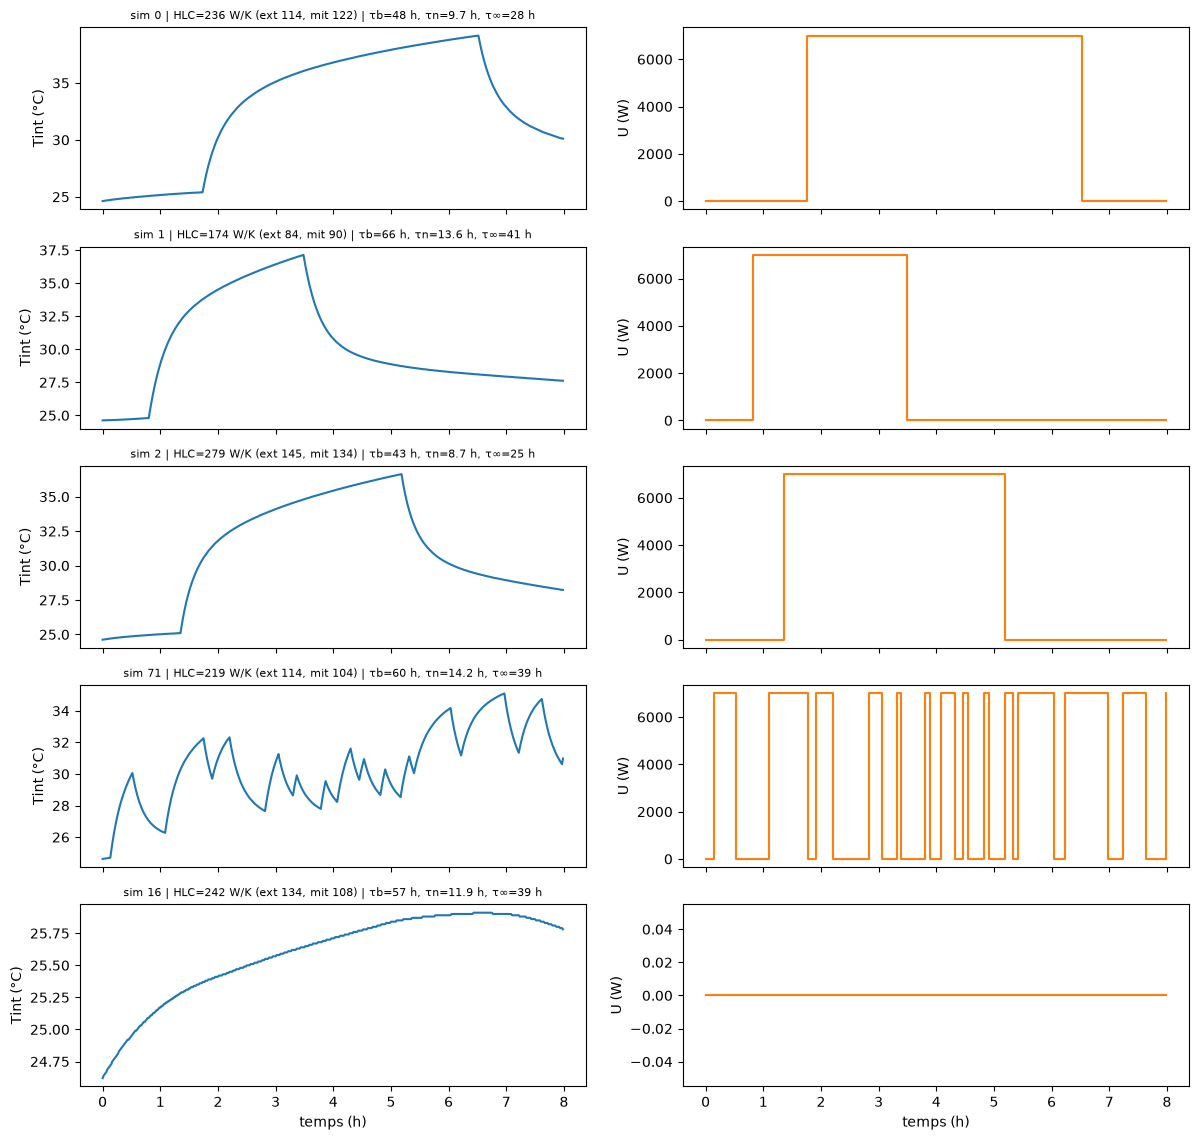

In [4]:
feats = excitation_features(eda.x[..., 1])
never = torch.nonzero(feats["never_on"]).squeeze(1)
busy = torch.nonzero(feats["n_switch"] > 20).squeeze(1)
examples = [0, 1, 2, int(busy[0]), int(never[0])]
plot_examples(eda, examples);

Toutes les excitations sont des **séquences binaires pseudo-aléatoires (PRBS)** : le chauffage alterne entre 0 et 7 000 W par blocs de durée aléatoire. Selon les paramètres, on obtient un unique créneau long, des commutations rapides, ou **aucune chauffe**. Même sans chauffe, $T_{int}$ évolue légèrement : c'est la relaxation de l'état thermique initial des parois (non à l'équilibre, comme dans l'article) et l'effet des conditions aux limites.

### 3.2 Distribution des indicateurs

In [5]:
target_table(eda.y)

,unité,count,mean,std,min,5%,50%,95%,max,skew
HLC,W/K,50000.0,233.02,31.21,124.76,183.53,231.95,286.24,364.72,0.18
HLC_ext,W/K,50000.0,112.48,17.17,59.21,84.70,112.24,141.06,184.56,0.10
HLC_mit,W/K,50000.0,120.54,26.14,51.45,80.40,118.92,166.23,225.48,0.28
tau_b,h,50000.0,49.96,10.06,23.80,35.60,48.77,68.25,111.83,0.70
tau_n,h,50000.0,11.04,2.01,5.60,8.22,10.78,14.72,23.35,0.76
tau_inf,h,50000.0,31.21,7.49,12.80,20.90,30.17,45.05,80.79,0.83


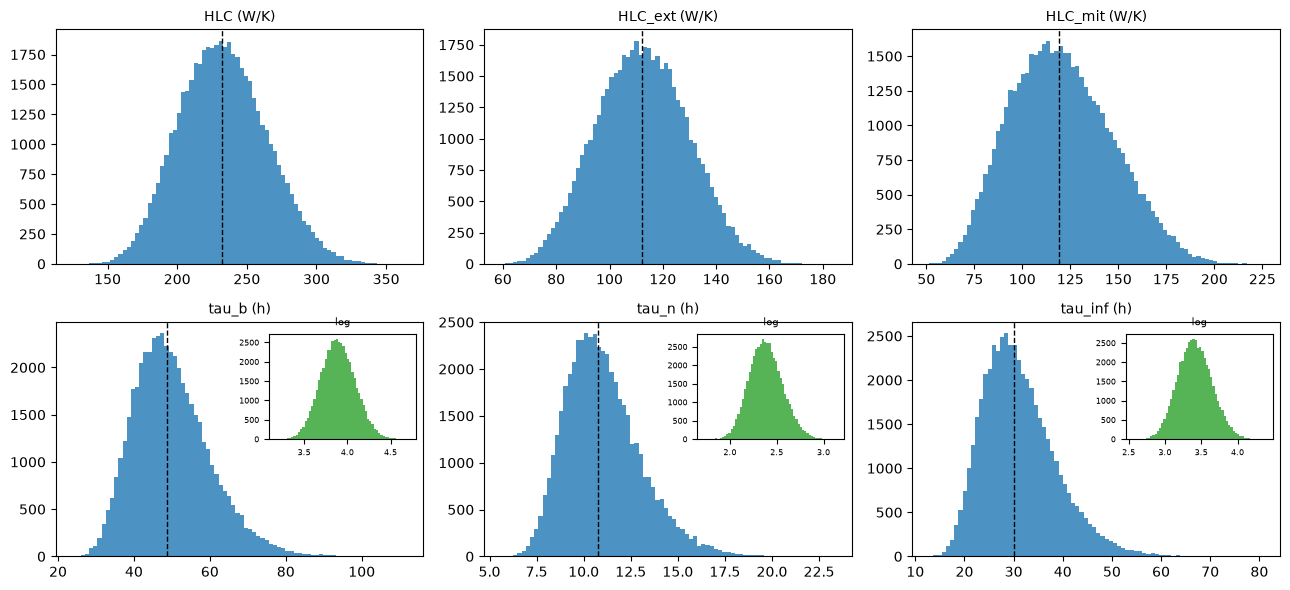

In [6]:
plot_target_distributions(eda.y);

- $\mathrm{HLC}$ (≈ 125–365 W/K, moyenne ≈ 233) et ses deux composantes ont des distributions proches de cloches symétriques, issues du tirage Monte-Carlo des paramètres thermophysiques autour de leurs valeurs nominales.
- Les trois constantes de temps sont **asymétriques à droite** (longue traîne vers les grandes valeurs). Leur logarithme est nettement plus symétrique (encarts verts) : on modélisera $\log \tau$.
- Les échelles diffèrent fortement (≈ 230 W/K contre ≈ 11 h) : les cibles seront **standardisées** pour qu'aucun indicateur ne domine la fonction de perte.

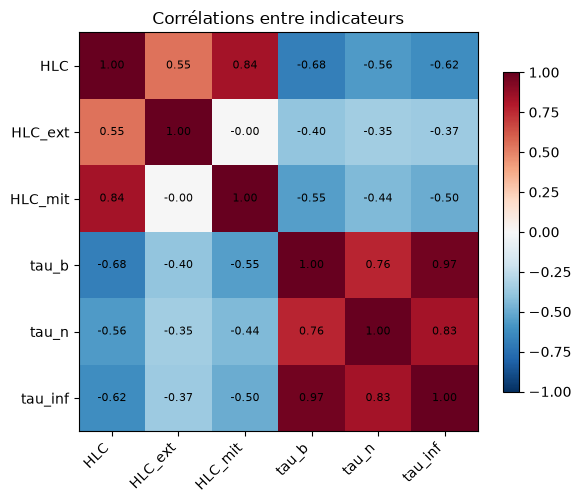

In [7]:
plot_correlation(eda.y);

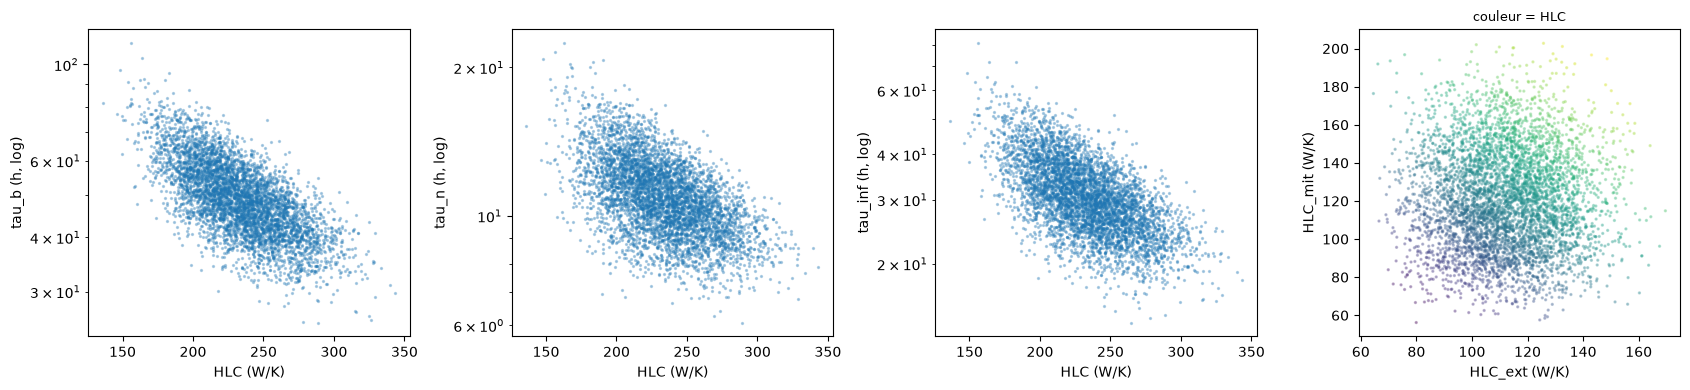

In [8]:
plot_physical_relations(eda.y);

**Lecture physique.**
- Les constantes de temps sont **anti-corrélées au HLC** (≈ −0,6 à −0,7), conformément à $\tau \approx C/\mathrm{HLC}$ : à capacité égale, un bâtiment plus déperditif réagit plus vite. La dispersion résiduelle provient des capacités thermiques, tirées indépendamment.
- $\tau_b$ et $\tau_\infty$ sont presque colinéaires (corrélation ≈ 0,97) ; $\tau_n$ l'est moins, car il ne dépend que de la pénétration du froid sur 8 h dans les couches proches de l'air.
- $\mathrm{HLC}_{ext}$ et $\mathrm{HLC}_{mit}$ sont **décorrélés** : connaître le HLC ne suffit pas à connaître sa répartition. La variance du HLC provient surtout de $\mathrm{HLC}_{mit}$ (corrélation 0,84 avec le HLC, contre 0,55 pour $\mathrm{HLC}_{ext}$). Séparer les deux composantes à partir de la seule température d'air sera probablement la partie la plus difficile du problème pour $H_b$.

### 3.3 L'excitation

Simulations sans aucune chauffe : 8.3%
Énergie injectée moyenne : 26.4 kWh sur 8 h


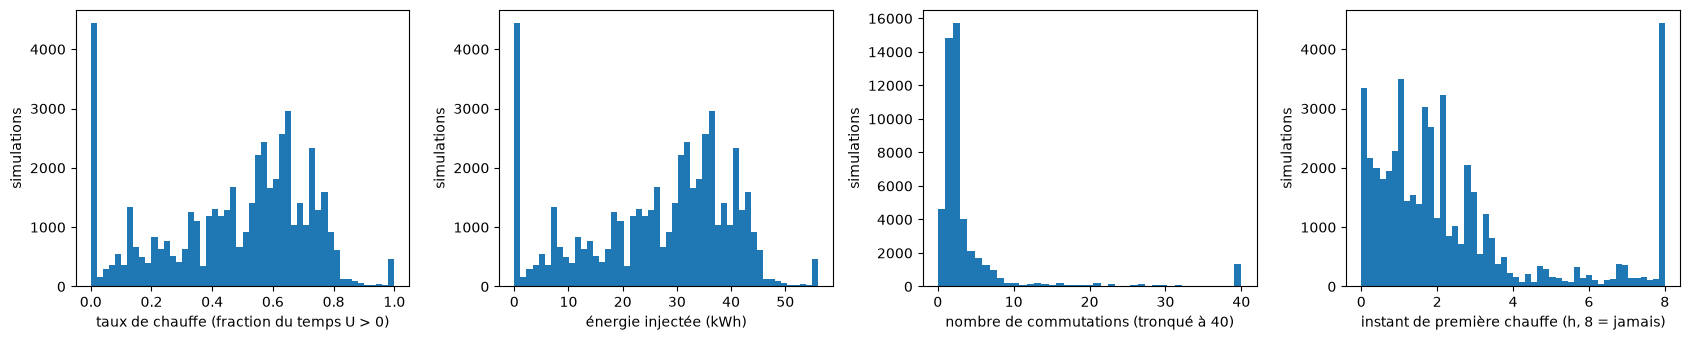

In [9]:
print(f"Simulations sans aucune chauffe : {feats['never_on'].float().mean():.1%}")
print(f"Énergie injectée moyenne : {feats['energy_kwh'].mean():.1f} kWh sur 8 h")
plot_excitation_summary(feats);

Seuls deux paramètres varient d'une simulation à l'autre : la probabilité d'être allumé (`prbs_probability_on`, 0,2 à 0,9) et la durée minimale des blocs (`prbs_min_duration_hours`, 0 à 2 h). La puissance est toujours 7 000 W et la graine identique.

Les distributions sont multimodales : le taux de chauffe va de 0 (jamais allumé) à 1 (allumé en continu, environ 1 % des cas, soit ≈ 56 kWh), et la plupart des signaux ne comportent que 1 à 4 commutations (créneaux longs) ; seule une minorité commute rapidement.

Conséquence importante : **environ 8,3 % des simulations ne chauffent jamais**. Pour celles-ci, le modèle ne voit qu'une évolution libre ; on s'attend à des erreurs nettement plus grandes, à analyser séparément (section 7).

### 3.4 Informativité de la réponse

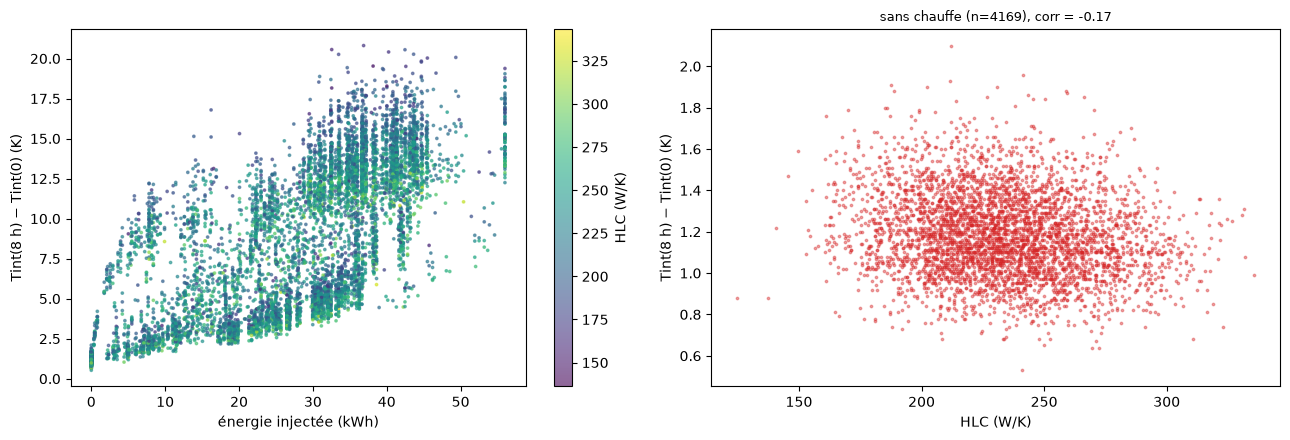

In [10]:
plot_informativeness(eda);

- **À gauche** : l'élévation finale dépend d'abord de l'énergie injectée, mais à énergie égale elle se répartit en **deux branches** : la branche haute correspond aux signaux encore en chauffe (ou arrêtés depuis peu) à 8 h, la branche basse aux signaux arrêtés plus tôt, dont la température a déjà relaxé. **Le moment où l'énergie est injectée compte autant que sa quantité.** L'effet du HLC, lui, n'est pas visible à l'œil : il est de second ordre devant celui de la forme de l'excitation.
- **À droite** : sans chauffe, la température monte quand même d'environ 1,2 K en 8 h (relaxation des parois initialement plus chaudes que l'air) et cette dérive n'est que faiblement liée au HLC (corrélation ≈ −0,17). Ces simulations contiennent donc très peu d'information sur le HLC : on s'attend à ce que le modèle y prédise une valeur proche de la moyenne.

Pour mesurer l'effet du HLC à excitation comparable, on calcule la corrélation entre élévation finale et HLC **à l'intérieur de chaque décile d'énergie injectée** (simulations chauffées uniquement) :

In [11]:
heated = ~feats["never_on"]
rise = eda.x[heated, -1, 0] - eda.x[heated, 0, 0]
conditional_correlation(feats["energy_kwh"][heated], rise, eda.y[heated, 0], n_bins=10)

,bin,min,max,n,corr
0,1,0.117,10.383,4572,-0.094
1,2,10.383,18.550,4527,-0.121
2,3,18.550,23.450,4626,-0.097
3,4,23.450,27.533,4589,-0.120
4,5,27.533,31.033,4116,-0.165
5,6,31.033,33.600,4886,-0.143
6,7,33.600,36.050,4634,-0.193
7,8,36.050,38.500,4555,-0.249
8,9,38.500,42.000,4471,-0.349
9,10,42.000,56.000,4855,-0.357


**Lecture.** La corrélation est **négative dans tous les déciles** : à énergie comparable, un bâtiment plus déperditif s'échauffe moins, comme attendu physiquement. Elle reste toutefois **faible** (de −0,09 à −0,36) et **croît avec l'énergie injectée** : plus on chauffe, plus la réponse est informative sur le HLC, ce qui rejoint l'idée de l'article d'optimiser l'excitation. Même dans le décile le plus énergétique, l'élévation finale n'explique qu'environ 12 % de la variance du HLC ($0{,}36^2$) : l'essentiel de l'information est contenu dans la **forme temporelle** de la réponse et dans sa chronologie par rapport à la chauffe. Un résumé statique (énergie, élévation finale) ne suffit donc pas : il faut un modèle qui lise toute la séquence $(T_{int}(t), U(t))$, ce qui motive l'architecture séquentielle CNN-GRU. On s'attend aussi à ce que l'erreur de prédiction **diminue avec l'énergie injectée** ; ce point sera vérifié en section 7.

In [12]:
summary = pd.read_csv(ARTIFACTS / "batch_summary.csv")
ks_cols = [c for c in summary.columns if c.startswith("ks_p_")]
n_low = int((summary[ks_cols].iloc[1:] < 0.01).sum().sum())
print(f"Tests KS avec p < 0,01 : {n_low} / {len(ks_cols) * (len(summary) - 1)}")
summary[["file", "frac_prbs", "frac_never_on", "mean_energy_kwh", "mean_HLC", "std_HLC", "mean_tau_b"]]

Tests KS avec p < 0,01 : 0 / 114


,file,frac_prbs,frac_never_on,mean_energy_kwh,mean_HLC,std_HLC,mean_tau_b
0,batch_1.pt,1.0,0.085,26.269,233.076,31.382,49.963
1,batch_2.pt,1.0,0.083,26.368,232.716,31.381,50.069
2,batch_3.pt,1.0,0.083,26.332,232.806,31.281,49.980
3,batch_4.pt,1.0,0.084,26.267,232.868,31.451,50.005
4,batch_5.pt,1.0,0.084,26.321,233.145,31.350,49.940
5,batch_6.pt,1.0,0.085,26.191,232.804,31.439,50.035
6,batch_7.pt,1.0,0.084,26.167,232.915,31.262,49.971
7,batch_8.pt,1.0,0.085,26.153,232.917,31.249,49.987
8,batch_9.pt,1.0,0.083,26.295,233.018,31.252,49.962
9,batch_10.pt,1.0,0.084,26.333,232.884,31.352,50.044


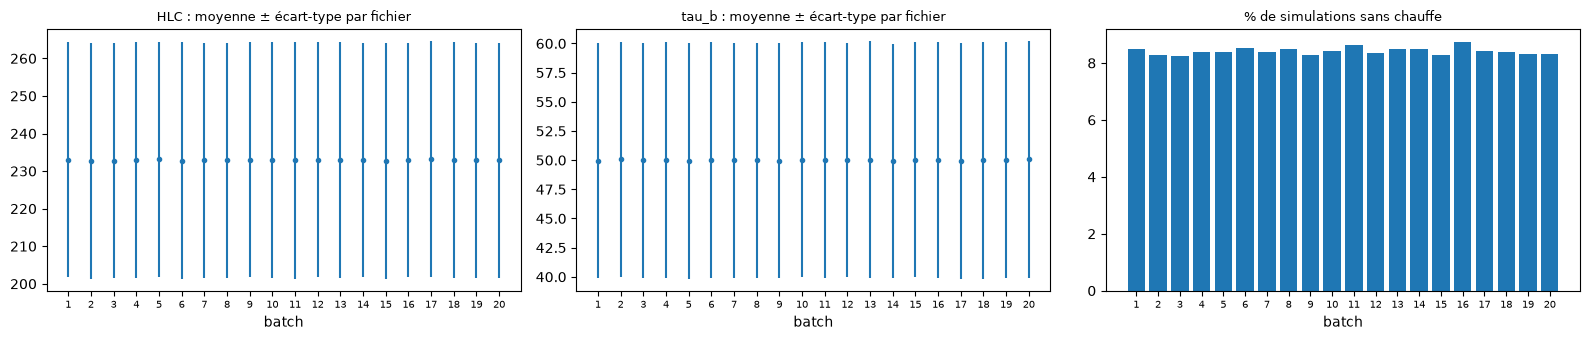

In [13]:
plot_batch_homogeneity(summary);

Les 20 fichiers sont **statistiquement indiscernables** : la moyenne du HLC varie de 232,7 à 233,2 W/K (pour un écart-type intra-fichier de 31 W/K), la part de simulations sans chauffe reste entre 8,3 % et 8,7 %, et aucun des 114 tests de Kolmogorov–Smirnov n'est significatif au seuil de 1 % (on en attendrait environ 1 par hasard). Tous les fichiers ne contiennent que des PRBS et 480 pas de temps.

### 3.6 Identifiabilité : quelle information les courbes contiennent-elles, et quand ?

Les sections précédentes décrivent les données ; celle-ci pose la question qui conditionne la modélisation : **pour chaque indicateur, quelle part de l'information est réellement présente dans 8 h de mesure, et à quel moment apparaît-elle ?** Trois analyses complémentaires, sans réseau de neurones, y répondent :

- **a) Expériences naturelles** : comparer des bâtiments soumis à *exactement* la même excitation, pour isoler l'effet du bâtiment ;
- **b) Plafond d'information linéaire** : une régression ridge sur la séquence brute donne un $R^2$ par indicateur et par durée d'observation ;
- **c) ACP des réponses** : dimension effective des courbes de température et lien des composantes avec les indicateurs.

#### a) Expériences naturelles : même excitation, bâtiments différents

Dans le cas général, la forme de l'excitation et le bâtiment varient simultanément, et leurs effets se mélangent (section 3.4). Or le champ `prbs_seed` vaut toujours 42 : la séquence aléatoire est la même pour toutes les simulations, et des paramètres PRBS voisins produisent des signaux **identiques à la minute près**. Les simulations jamais chauffées ($U \equiv 0$) et celles chauffées en continu ($U \equiv 7\,000$ W, réponse indicielle) forment aussi des groupes d'excitation identique.

À l'intérieur d'un tel groupe, **toute différence de $T_{int}$ est due au bâtiment seul** : c'est une expérience contrôlée cachée dans le jeu de données.

C'est d'ailleurs exactement le cadre de la phase 2 de l'article : une seule excitation, imposée sur site, et une population de bâtiments simulés.

In [14]:
u_eda = eda.x[..., 1]
group, sizes = group_identical_excitations(u_eda)
in_shared = sizes[group] >= 2
print(f"{sizes.numel()} excitations distinctes pour {len(eda)} simulations")
print(f"Simulations partageant leur excitation avec au moins une autre : {in_shared.float().mean():.1%}")
print(f"Groupes de taille >= 50 : {(sizes >= 50).sum().item()}")
groups_tbl = excitation_groups_table(u_eda, group, sizes, top=15)
groups_tbl

2222 excitations distinctes pour 50000 simulations
Simulations partageant leur excitation avec au moins une autre : 99.1%
Groupes de taille >= 50 : 200


,groupe,taille,type,taux de chauffe,commutations,énergie (kWh)
0,0,4169,jamais chauffé,0.000,0,0.0
1,1,749,PRBS,0.656,1,36.8
2,2,676,PRBS,0.654,1,36.6
3,3,466,PRBS,0.738,1,41.3
4,4,461,chauffe continue,1.000,0,56.0
5,5,455,PRBS,0.581,1,32.5
6,6,447,PRBS,0.579,1,32.4
7,7,442,PRBS,0.621,1,34.8
8,8,310,PRBS,0.619,1,34.7
9,9,310,PRBS,0.665,1,37.2


{'Jamais chauffé': 4169, 'Chauffe continue (réponse indicielle)': 461, 'PRBS le plus fréquent': 749}


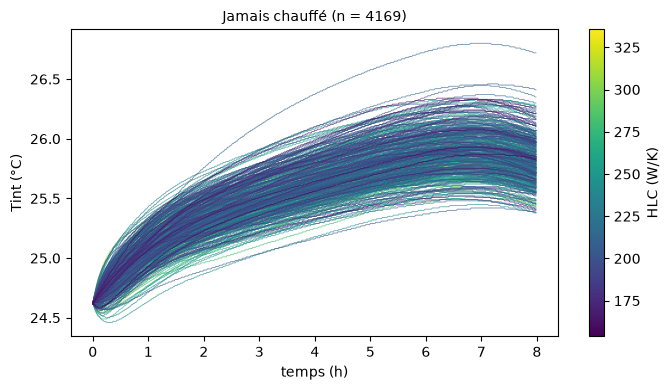

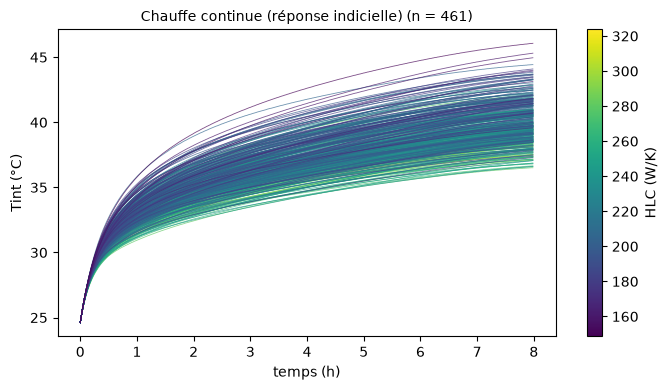

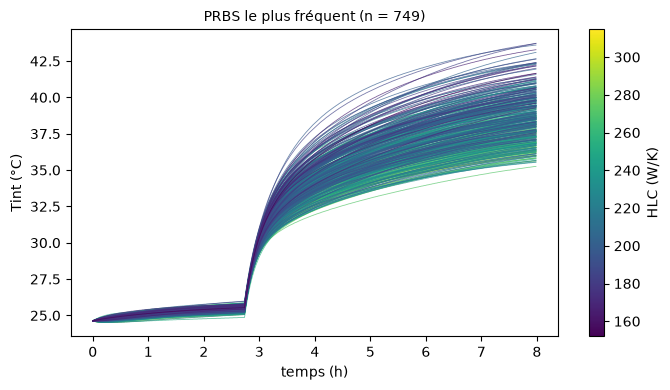

In [15]:
def first_group(kind: str) -> int | None:
    rows = groups_tbl[groups_tbl["type"] == kind]
    return int(rows["groupe"].iloc[0]) if len(rows) else None

chosen = {
    "Jamais chauffé": first_group("jamais chauffé"),
    "Chauffe continue (réponse indicielle)": first_group("chauffe continue"),
    "PRBS le plus fréquent": first_group("PRBS"),
}
# a correlation needs enough buildings: keep groups with at least 30 simulations
chosen = {k: g for k, g in chosen.items() if g is not None and sizes[g] >= 30}
print({k: int(sizes[g]) for k, g in chosen.items()})

timelines = {}
for name, g in chosen.items():
    m = group == g
    plot_group_responses(eda.x[m, :, 0], eda.y[m], name)
    timelines[f"{name} (n = {int(m.sum())})"] = information_timeline(eda.x[m, :, 0], eda.y[m])

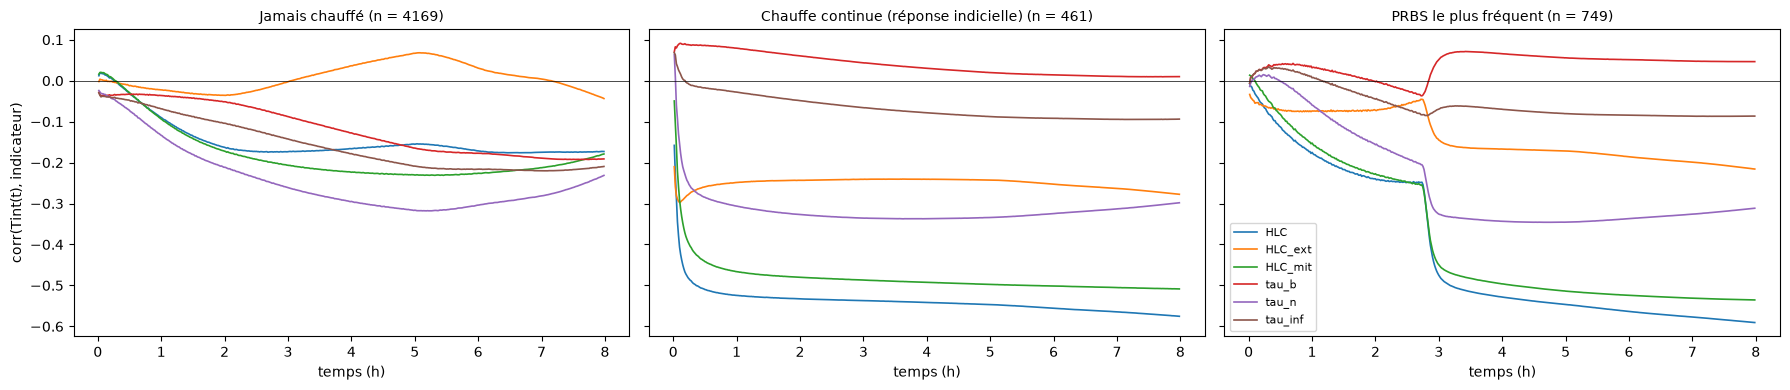

In [16]:
plot_information_timelines(timelines);

In [17]:
# Corrélation atteinte à 1 h, 4 h et 8 h, par groupe et par indicateur
pd.concat(
    {name: df.iloc[[59, 239, 479]] for name, df in timelines.items()}, names=["groupe"]
).round(2)

HLC  HLC_ext  \
groupe                                          temps (h)                  
Jamais chauffé (n = 4169)                       0.983     -0.09    -0.02   
                                                3.983     -0.17     0.04   
                                                7.983     -0.17    -0.04   
Chauffe continue (réponse indicielle) (n = 461) 0.983     -0.52    -0.25   
                                                3.983     -0.54    -0.24   
                                                7.983     -0.58    -0.28   
PRBS le plus fréquent (n = 749)                 0.983     -0.18    -0.08   
                                                3.983     -0.53    -0.17   
                                                7.983     -0.59    -0.22   

                                                           HLC_mit  tau_b  \
groupe                                          temps (h)                   
Jamais chauffé (n = 4169)                       0.983        -0.09  -0.04   
                                                3.983        -0.22  -0.13   
                                                7.983        -0.18  -0.19   
Chauffe continue (réponse indicielle) (n = 461) 0.983        -0.47   0.08   
                                                3.983        -0.49   0.03   
                                                7.983        -0.51   0.01   
PRBS le plus fréquent (n = 749)                 0.983        -0.15   0.04   
                                                3.983        -0.50   0.07   
                                                7.983        -0.54   0.05   

                                                           tau_n  tau_inf  
groupe                                          temps (h)                  
Jamais chauffé (n = 4169)                       0.983      -0.13    -0.07  
                                                3.983      -0.30    -0.18  
                                                7.983      -0.23    -0.21  
Chauffe continue (réponse indicielle) (n = 461) 0.983      -0.31    -0.03  
                                                3.983      -0.34    -0.08  
                                                7.983      -0.30    -0.09  
PRBS le plus fréquent (n = 749)                 0.983      -0.06     0.01  
                                                3.983      -0.34    -0.07  
                                                7.983      -0.31    -0.09

**Lecture.**

**Une structure cachée du jeu de données.** Les 50 000 simulations de l'échantillon n'utilisent que **2 222 excitations distinctes**, et 99,1 % d'entre elles partagent leur excitation avec au moins une autre. La plupart des grands groupes sont des **échelons retardés** : chauffage éteint, puis allumé à un instant donné jusqu'à la fin (une seule commutation). Conséquence directe pour l'évaluation : les fichiers de test contiennent de nouveaux bâtiments, mais pas de nouvelles excitations. Le score de test mesure la généralisation **à de nouveaux bâtiments**, pas à des excitations inédites ; on ajoutera en section 7 une évaluation sur des excitations tenues à l'écart.

**Pas d'excitation, pas d'information.** Dans le groupe PRBS le plus fréquent (chauffe à partir de 2,75 h), la corrélation entre $T_{int}(t)$ et le HLC reste faible tant que le chauffage est éteint (≈ −0,25), puis **saute à ≈ −0,5 dans les minutes qui suivent l'allumage**. Pour la réponse indicielle, ce niveau est atteint en moins d'une demi-heure, puis ne progresse plus que lentement (−0,52 à 1 h, −0,58 à 8 h). Sans chauffe, la corrélation plafonne à ≈ −0,17. L'information sur les déperditions arrive donc avec la sollicitation, et surtout dans la **réponse rapide de l'air** juste après une commutation.

**Capacité et déperdition se compensent.** Dans la réponse indicielle, $\tau_b$ est quasiment décorrélé de $T_{int}(t)$ à tout instant (|corr| < 0,1), alors qu'il est fortement anti-corrélé au HLC (−0,68). Physiquement, un bâtiment à forte inertie (grand $\tau_b$) s'échauffe plus lentement, mais il a aussi en moyenne un HLC plus faible, ce qui le fait s'échauffer davantage : **les deux effets s'annulent sur une valeur ponctuelle**. Ce n'est pas l'amplitude de la réponse qui sépare capacité et déperdition, c'est sa **forme** (vitesse initiale contre pente tardive). C'est le problème classique d'identifiabilité des modèles RC sur fenêtre courte, et un argument de plus pour un modèle qui lit toute la courbe.

**$\mathrm{HLC}_{ext}$ et $\mathrm{HLC}_{mit}$ ne se distinguent pas instant par instant** : leurs corrélations avec $T_{int}(t)$ ont le même signe et la même dynamique, avec une amplitude proportionnelle à leur part dans la variance du HLC (−0,51 pour mit, −0,28 pour ext à 8 h). Une lecture ponctuelle ne renseigne donc que sur la **somme** des déperditions. Les parties b) et c) montrent cependant qu'une **combinaison** de plusieurs instants permet de les séparer en partie : l'information sur leur répartition est contenue dans la forme de la courbe, pas dans son niveau.

#### b) Référence linéaire : que capte une régression ridge ?

On ajuste une **régression ridge** de la séquence brute (les $2 \times 60\,h$ valeurs de $T_{int}$ et $U$ sur les $h$ premières heures) vers les six indicateurs, puis on mesure le $R^2$ sur des données non vues. Protocole :
- apprentissage sur les simulations de l'échantillon EDA issues des **fichiers d'entraînement**, évaluation sur celles des **fichiers de validation** : le jeu de test reste intact ;
- constantes de temps ajustées en $\log$ (comme pour le modèle principal), $R^2$ calculé en unités physiques ;
- pénalité choisie par validation interne.

Ce $R^2$ est une **référence basse** de ce qu'un modèle plus riche peut atteindre ; en faisant varier $h$, il montre comment l'information exploitable linéairement s'accumule avec la durée d'essai. On le compare ensuite au même modèle ajusté **à excitation fixée**, à l'intérieur des groupes identifiés en a).

In [18]:
split_eda = SplitSpec()
tr = torch.isin(eda.batch_id, torch.tensor(split_eda.train))
va = torch.isin(eda.batch_id, torch.tensor(split_eda.val))
hours = (0.5, 1, 2, 4, 6, 8)

ridge_all = ridge_information_curve(eda.x[tr], eda.y[tr], eda.x[va], eda.y[va], hours=hours)
ridge_all

,alpha,HLC,HLC_ext,HLC_mit,tau_b,tau_n,tau_inf
fenêtre (h),,,,,,,
0.5,0.00,0.046,0.005,0.042,-0.012,0.010,-0.016
1.0,0.00,0.076,0.010,0.065,-0.012,0.030,-0.015
2.0,0.00,0.147,0.021,0.129,-0.014,0.052,-0.017
4.0,0.01,0.220,0.035,0.192,-0.014,0.084,-0.015
6.0,0.10,0.240,0.040,0.207,-0.013,0.088,-0.011
8.0,0.10,0.258,0.053,0.214,-0.013,0.088,-0.011


,alpha,HLC,HLC_ext,HLC_mit,tau_b,tau_n,tau_inf
fenêtre (h),,,,,,,
0.5,0.0,0.048,0.005,0.044,-0.010,0.014,-0.013
1.0,0.0,0.080,0.011,0.069,-0.010,0.034,-0.012
2.0,0.0,0.157,0.022,0.138,-0.012,0.058,-0.015
4.0,0.1,0.229,0.037,0.200,-0.010,0.093,-0.010
6.0,0.1,0.259,0.045,0.223,-0.010,0.097,-0.008
8.0,0.1,0.279,0.058,0.231,-0.011,0.096,-0.008


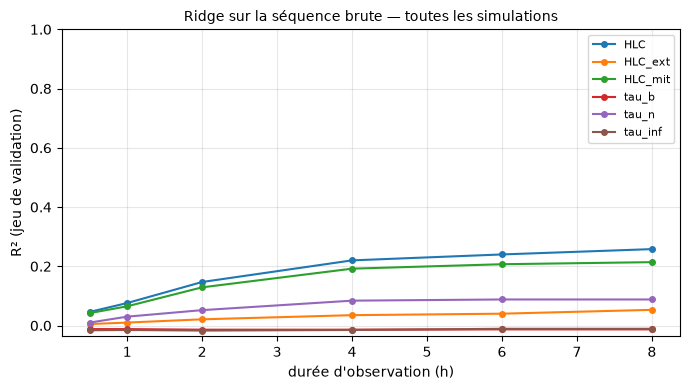

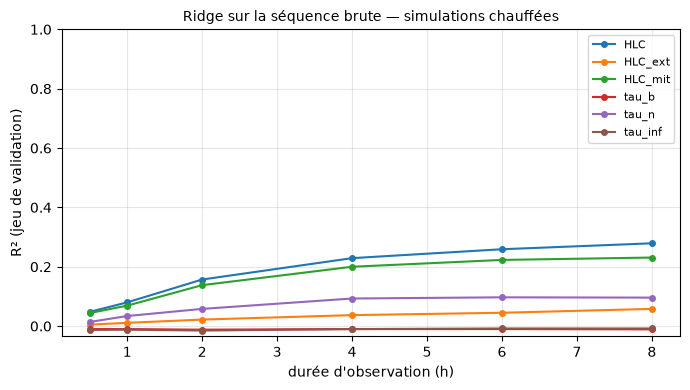

In [19]:
heat_tr, heat_va = tr & ~feats["never_on"], va & ~feats["never_on"]
ridge_heated = ridge_information_curve(eda.x[heat_tr], eda.y[heat_tr], eda.x[heat_va], eda.y[heat_va], hours=hours)
fig = plot_information_curve(ridge_all, "Ridge sur la séquence brute — toutes les simulations")
fig = plot_information_curve(ridge_heated, "Ridge sur la séquence brute — simulations chauffées")
ridge_heated

In [20]:
# Même régression ridge, mais à excitation fixée (à l'intérieur de chaque groupe), découpage aléatoire 75/25
gen = torch.Generator().manual_seed(SEED)
ridge_groups = {}
for name, g in chosen.items():
    idx = torch.nonzero(group == g).squeeze(1)
    idx = idx[torch.randperm(idx.numel(), generator=gen)]
    cut = int(0.75 * idx.numel())
    a, b = idx[:cut], idx[cut:]
    ridge_groups[name] = ridge_information_curve(eda.x[a], eda.y[a], eda.x[b], eda.y[b], hours=(1, 2, 4, 8))
pd.concat(ridge_groups, names=["groupe"])

alpha    HLC  HLC_ext  \
groupe                                fenêtre (h)                          
Jamais chauffé                        1            0.010  0.031   -0.005   
                                      2            0.010  0.042   -0.001   
                                      4            0.001  0.110    0.323   
                                      8            0.001  0.179    0.427   
Chauffe continue (réponse indicielle) 1            0.100  0.342    0.115   
                                      2            0.100  0.356    0.120   
                                      4            0.000  0.408    0.289   
                                      8            0.000  0.495    0.500   
PRBS le plus fréquent                 1            1.000  0.039   -0.015   
                                      2            1.000  0.049   -0.015   
                                      4            0.001  0.353    0.299   
                                      8            0.001  0.425    0.451   

                                                   HLC_mit  tau_b  tau_n  \
groupe                                fenêtre (h)                          
Jamais chauffé                        1              0.042 -0.005  0.070   
                                      2              0.051  0.003  0.085   
                                      4              0.069  0.106  0.160   
                                      8              0.121  0.140  0.182   
Chauffe continue (réponse indicielle) 1              0.235  0.009 -0.014   
                                      2              0.241  0.018 -0.000   
                                      4              0.106  0.022  0.057   
                                      8              0.229  0.107  0.186   
PRBS le plus fréquent                 1              0.017 -0.015  0.016   
                                      2              0.027 -0.005  0.081   
                                      4              0.204  0.090  0.208   
                                      8              0.211  0.100  0.215   

                                                   tau_inf  
groupe                                fenêtre (h)           
Jamais chauffé                        1              0.002  
                                      2              0.012  
                                      4              0.082  
                                      8              0.095  
Chauffe continue (réponse indicielle) 1             -0.018  
                                      2             -0.002  
                                      4              0.021  
                                      8              0.082  
PRBS le plus fréquent                 1             -0.015  
                                      2              0.005  
                                      4              0.068  
                                      8              0.074

**Lecture.**

**Toutes excitations confondues, un modèle linéaire échoue.** À 8 h, la ridge n'explique que 26 % de la variance du HLC, 21 % pour $\mathrm{HLC}_{mit}$, 5 % pour $\mathrm{HLC}_{ext}$ et environ 9 % pour $\tau_n$ ; pour $\tau_b$ et $\tau_\infty$, le $R^2$ est nul, voire légèrement négatif. Pour le HLC, l'information exploitable croît avec la durée jusqu'à environ 4 h (0,05 à 0,5 h, 0,22 à 4 h), puis plafonne (0,26 à 8 h).

**Pourquoi ?** Un modèle linéaire affecte un poids fixe à chaque minute, identique pour les 2 222 excitations. Or a) montre que l'information apparaît **juste après l'allumage**, dont l'instant change d'une excitation à l'autre : la minute informative n'est jamais la même. Ce faible $R^2$ ne mesure donc pas l'absence d'information, mais l'incapacité d'un modèle linéaire à **conditionner la lecture de $T_{int}$ sur $U$**.

**À excitation fixée, le même modèle linéaire fait beaucoup mieux.** Ajustée à l'intérieur d'un groupe d'excitation identique (tableau ci-dessus), la ridge atteint à 8 h un $R^2$ de 0,50 pour le HLC sur la réponse indicielle et de 0,43 sur le groupe PRBS le plus fréquent (contre 0,26 tous groupes confondus). Pour $\mathrm{HLC}_{ext}$, il passe de 0,05 à 0,45–0,50, et les constantes de temps deviennent partiellement prévisibles ($\tau_n \approx 0{,}2$, $\tau_b \approx 0{,}1$). L'information est donc bien présente dans les courbes : c'est le **mélange des excitations** qui la rend inexploitable par un modèle linéaire.

Trois enseignements complémentaires :
- **L'information suit l'excitation.** Dans le groupe PRBS (allumage à 2,75 h), le $R^2$ reste nul tant que la fenêtre se limite aux 2 premières heures, puis bondit dès qu'elle inclut l'allumage (0,35 pour le HLC à 4 h).
- **Les deux composantes du HLC ont des signatures différentes dans la forme de la courbe.** À excitation fixée, $\mathrm{HLC}_{ext}$ est mieux prévisible que $\mathrm{HLC}_{mit}$ (0,45–0,50 contre 0,21–0,23), alors que leurs corrélations instantanées étaient indiscernables (partie a). Même sans chauffe, la dérive libre renseigne davantage sur $\mathrm{HLC}_{ext}$ ($R^2 = 0{,}43$) que sur le HLC total (0,18), ce qui suggère que la relaxation des parois vers les conditions extérieures porte une signature propre des déperditions vers l'extérieur.
- **Les constantes de temps restent difficiles** ($R^2 \le 0{,}2$) même à excitation fixée : 8 h d'observation restent courtes devant $\tau_b \approx 50$ h.

Ces groupes ne comptent que 461 à 4 169 simulations, dont 25 % en évaluation (115 à 1 040), pour 480 variables : ces $R^2$ sont des ordres de grandeur, à ±0,1 près environ.

**Conséquence.** Le modèle doit traiter conjointement $T_{int}$ et $U$ et capter leurs **interactions non linéaires** dans le temps : c'est précisément ce que permettent une convolution sur les deux canaux suivie d'une couche récurrente. Ces $R^2$ serviront de référence à battre en section 6.

#### c) ACP des réponses en température

On applique une analyse en composantes principales aux courbes $T_{int}(t)$ : d'abord sur un échantillon de toutes les simulations (variabilité due à l'excitation **et** au bâtiment), puis sur le groupe à chauffe continue (variabilité due au **bâtiment seul**).

Composantes pour 99 % de variance : 12


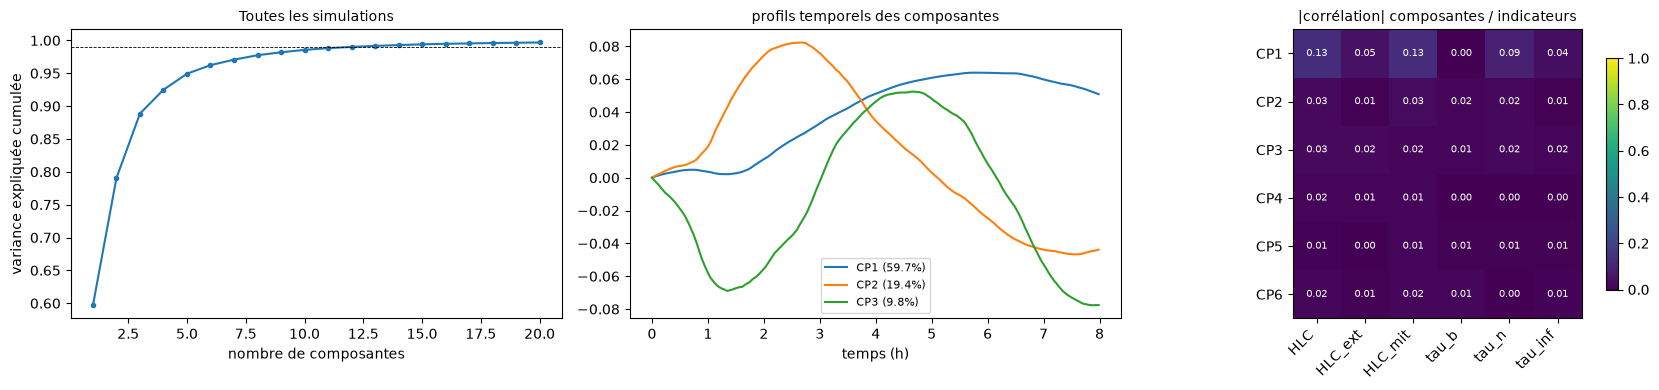

In [21]:
res_all = pca(eda.x[:20_000, :, 0], k=20)
plot_pca(res_all, eda.y[:20_000], "Toutes les simulations");
print("Composantes pour 99 % de variance :", int((res_all.explained.cumsum(0) < 0.99).sum()) + 1)

Composantes pour 99 % de variance : 2


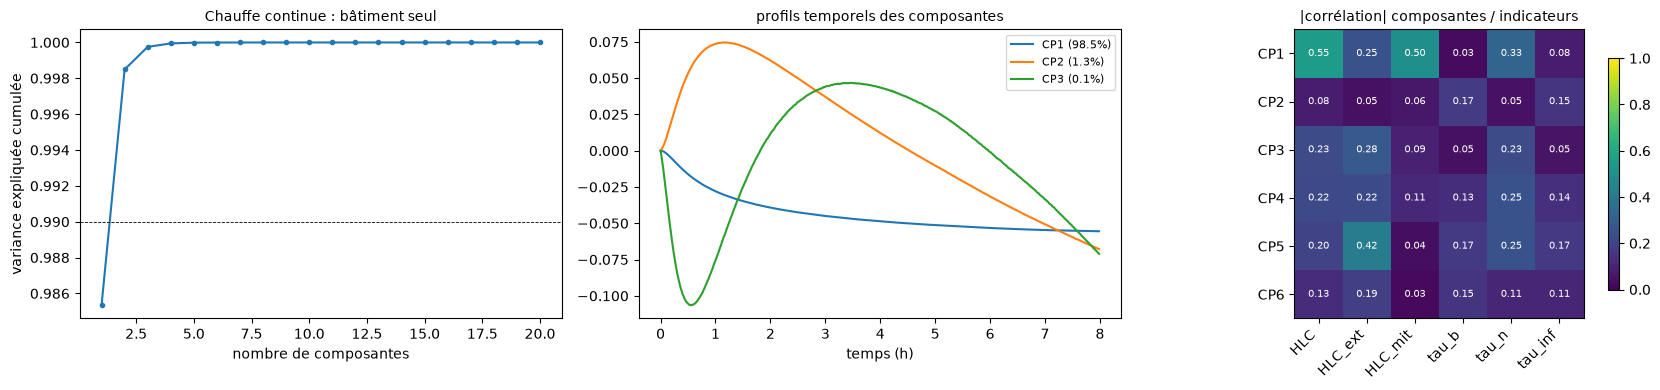

In [22]:
g_step = chosen.get("Chauffe continue (réponse indicielle)")
if g_step is not None:
    m = group == g_step
    res_step = pca(eda.x[m, :, 0], k=20)
    plot_pca(res_step, eda.y[m], "Chauffe continue : bâtiment seul")
    print("Composantes pour 99 % de variance :", int((res_step.explained.cumsum(0) < 0.99).sum()) + 1)

**Lecture.**

**Toutes simulations confondues, la variance des courbes est celle de l'excitation.** Il faut 12 composantes pour 99 % de la variance, et leurs profils temporels décrivent *quand* la chauffe a lieu (montée précoce, tardive, alternances). Aucune n'est corrélée à plus de 0,13 avec un indicateur : **ce qui fait varier le plus les courbes n'est pas le bâtiment**, ce qui confirme les conclusions de 3.4 et de la partie b).

**À excitation fixée, l'effet du bâtiment est de très faible dimension.** Pour la réponse indicielle, une seule composante explique 98,5 % de la variance et trois en expliquent 99,97 %. La première est l'**amplitude** de la montée : elle porte l'essentiel de l'information sur le HLC (|corr| = 0,55), surtout via $\mathrm{HLC}_{mit}$ (0,50), et sur $\tau_n$ (0,33).

**Mais l'information fine est dans des composantes de très faible variance.** $\mathrm{HLC}_{ext}$ est surtout lié à CP3 et CP5 (|corr| = 0,28 et 0,42), qui représentent ensemble moins de 0,1 % de la variance : ce sont de subtiles différences de **forme**, en particulier dans la première heure (creux de CP3 vers 0,5 h). $\tau_b$ n'est lié qu'à CP2 (0,17). Deux conséquences pratiques :
- **ne pas compresser les entrées par ACP** (ou toute réduction fondée sur la variance), qui éliminerait précisément les composantes utiles pour $\mathrm{HLC}_{ext}$ et les constantes de temps ;
- **ces différences de forme sont petites, donc fragiles au bruit de mesure** : avec une incertitude capteur de ±0,25 °C (article), une partie de cette information pourrait disparaître. On s'attend à ce que $\mathrm{HLC}_{ext}$ et les $\tau$ soient les plus sensibles au bruit, ce qui sera testé en section 7.

### 3.7 Synthèse de l'EDA et conséquences pour la modélisation

| Constat | Conséquence |
|---|---|
| $\mathrm{HLC} = \mathrm{HLC}_{ext} + \mathrm{HLC}_{mit}$ exactement | prédire les deux composantes et **calculer** le HLC comme leur somme |
| $\tau_n \le \tau_\infty \le \tau_b$ toujours | paramétrer $\tau_\infty = \tau_n + \delta_1$, $\tau_b = \tau_\infty + \delta_2$ avec $\delta_i > 0$ |
| Cibles positives, $\tau$ asymétriques | sorties positives (softplus), perte sur $\log\tau$ standardisé |
| Échelles très différentes | standardisation des cibles, perte multi-tâche pondérée par famille |
| Réponse transitoire, 8 h ≪ τ | modèle séquentiel (CNN pour les motifs locaux + GRU pour la dynamique longue) |
| $T_{int}(0)$ constant | aucune information dans le niveau initial, seule la dynamique compte |
| 8,4 % sans chauffe | évaluation séparée de ce sous-groupe |
| Fichiers i.i.d. | découpage par fichier sans fuite ni biais de distribution |
| Seulement ≈ 2 200 excitations distinctes, partagées entre fichiers | le test mesure la généralisation à de **nouveaux bâtiments** ; ajouter une évaluation sur des **excitations tenues à l'écart** |
| L'information apparaît avec la chauffe, juste après l'allumage | pas d'excitation, pas d'information ; le modèle doit lire $T_{int}$ **conditionnellement à** $U$ |
| Ridge : $R^2$ du HLC 0,26 toutes excitations, ≈ 0,5 à excitation fixée | modèle **non linéaire** traitant conjointement $T_{int}$ et $U$ ; ces $R^2$ sont la référence à battre |
| Capacité et déperdition se compensent sur l'amplitude | seule la **forme** de la réponse les sépare : lire toute la séquence |
| $\mathrm{HLC}_{ext}$ et $\tau$ portés par des composantes de très faible variance | pas de réduction de dimension par ACP ; tester la **robustesse au bruit capteur** |
| $\tau$ peu identifiables en 8 h ($R^2 \le 0{,}2$ en linéaire) | attentes modestes sur les $\tau$, métriques rapportées par famille |

## 4. Protocole expérimental

**Découpage.** Les fichiers étant i.i.d., on découpe **par fichier** : 14 pour l'entraînement, 3 pour la validation (sélection des hyperparamètres et *early stopping*) et 3 pour le test, utilisés une seule fois à la fin. Aucune simulation ne peut ainsi apparaître dans deux ensembles.

In [23]:
split = SplitSpec()
print("train :", [files[i].name for i in split.train])
print("val   :", [files[i].name for i in split.val])
print("test  :", [files[i].name for i in split.test])

train : ['batch_1.pt', 'batch_2.pt', 'batch_3.pt', 'batch_4.pt', 'batch_5.pt', 'batch_6.pt', 'batch_7.pt', 'batch_8.pt', 'batch_9.pt', 'batch_10.pt', 'batch_11.pt', 'batch_12.pt', 'batch_13.pt', 'batch_14.pt']
val   : ['batch_15.pt', 'batch_16.pt', 'batch_17.pt']
test  : ['batch_18.pt', 'batch_19.pt', 'batch_20.pt']


**Normalisation** (`hlcnet.data.Normalizer`, ajustée sur l'entraînement uniquement) :
- entrées : standardisation par canal ($T_{int}$, $U$) ;
- cibles : $\log$ sur les trois constantes de temps, puis standardisation par colonne. Les prédictions sont ramenées en unités physiques (W/K, h) avant le calcul des métriques.

**Robustesse au bruit.** Comme dans l'article, on pourra ajouter pendant l'entraînement un bruit gaussien sur $T_{int}$ pour imiter l'incertitude des capteurs (`hlcnet.data.add_sensor_noise`).

**Métriques, par indicateur et par famille** (HLC et $H_b$ en W/K, CDT en h) : RMSE, MAE, erreur relative (MAPE), $R^2$, et **95ᵉ percentile de l'erreur absolue** (le critère retenu par coEnergy dans l'article). On vérifiera aussi le respect des contraintes physiques par les prédictions.

## 5. Modèles

*À compléter (phase 2) : baseline, puis CNN-GRU à contraintes physiques.*

## 6. Résultats

*À compléter.*

## 7. Analyse critique des erreurs

*À compléter : erreurs par famille, en fonction de l'énergie injectée, simulations sans chauffe, pires cas, robustesse au bruit.*

## 8. Conclusion et perspectives

*À compléter.*